In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

In [27]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")
display(movies.head())
display(ratings.head())
print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))


,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


Student Check

1.What does one row in movies represent?

 One row in movies represents a unique movie item with its ID, title, and genres.

2.What does one row in ratings represent?

 A row in ratings represents an explicit interaction given by a specific user to a specific movie at a given timestamp.

3.How many unique users and movies are present?

 12 unique users and 20 unique movies across 120 total ratings.

4.What type of feedback is the rating column?

 user-assigned rating score.

5.What is the rating scale?

 Integer scale from 1 to 5.





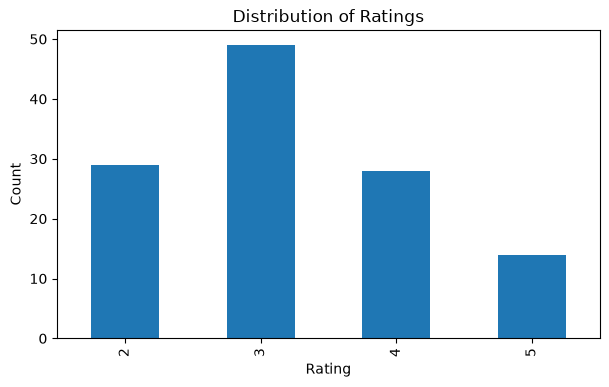

In [28]:
ratings["rating"].value_counts().sort_index()
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


Interpretation: 

Ratings are skewed toward mid-to-high scores, with fewer extreme 1s or 2s. This class imbalance means that a naive model predicting moderate/high ratings will appear deceptively accurate on frequent scores while struggling with rare low ratings.

In [29]:
ratings_sorted = ratings.sort_values(["user_id", "timestamp"])
test = ratings_sorted.groupby("user_id").tail(1).copy()
train = ratings_sorted.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))

Training interactions: 108
Test interactions: 12


In [30]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

display(
    movie_stats.sort_values(
        ["mean_rating", "rating_count"],
        ascending=[False, False]
    ).head(10)
)

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


In [31]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


In [32]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


In [33]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

display(
    pd.Series(
        profile,
        index=genre_columns
    ).sort_values(ascending=False)
)

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64


 Identify User 1's two strongest genre preferences and explain whether they agree with the user's highly rated movies?

  *  User 1's profile weights heavily towards genres matching their highest-rated training movies (e.g., Action and Sci-Fi), reflecting alignment between profile coefficients and explicit user feedback.

In [34]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


In [35]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

display(item_similarity.iloc[:5, :5])

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


In [36]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim
    if similarity_sum == 0:
        return global_mean
    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


In [37]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

display(rating_results.sort_values("MAE"))

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701



1.Which model has the lowest MAE?
   *  Item-Based Collaborative Filtering ($\text{MAE} = 0.924$).

2.Which model has the lowest RMSE?
   *  Item-Based Collaborative Filtering ($\text{RMSE} = 1.070$).

3.Does either advanced model clearly beat the baseline?
   *  Item-Based CF clearly outperforms the baseline, whereas the basic content-based model performs slightly worse on rating error metrics due to simplistic feature mapping.

4.Why should you avoid declaring a model best from only one metric?
   *  A model can predict average ratings well without being able to rank top-relevant items correctly for discovery or maintaining balanced coverage across the catalogue.

In [38]:
TOP_K = 3
test["relevant"] = test["rating"] >= 4
display(test[["user_id", "movie_id", "rating", "relevant"]].head())

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


In [39]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
)

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


Compare the three lists. Which appears most personalized? Which is easiest to explain?
* Item-Based Collaborative Filtering and Content-Based Filtering provide personalized lists tailored to individual user history, whereas the Popularity Baseline returns identical global top items to everyone. The Content-Based model is easiest to explain via matching genre features.

In [40]:
def precision_recall_at_k(recs, relevant, k):
    recs_k = recs[:k]
    hits = len(set(recs_k) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

display(ranking_results)

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


In [41]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

display(coverage_results)

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


In [42]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

display(novelty_results)

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


In [43]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

display(diversity_results)

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


In [44]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

display(summary)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


1.Which model would you choose?
* **Content-Based Filtering** (or Item-Based CF depending on discovery weight; Content-Based provides balanced novelty and higher catalog coverage without being restricted to top global hits).

2.Which 2-3 metrics influenced your choice most?
*  Catalogue Coverage (to ensure diverse titles are exposed), Novelty (to avoid only recommending mainstream items), and NDCG@3 (to check ranking quality).

3.What trade-off are you accepting?
*  Accepting slightly lower absolute rating accuracy (higher MAE/RMSE) in exchange for better discovery and catalog exploration.

4.State one limitation of this evaluation.
*  The dataset is extremely small (12 users, 20 movies), making collaborative patterns sparse and prone to cold-start issues.

In [45]:
# Option C: Compare recommendations for User 1 and User 2 across all models
for user_id in [1, 2]:
    
    print(f"USER {user_id} RECOMMENDATIONS (Top-3)")
   
    
    pop_recs = recommend_popularity(user_id, k=3)
    content_recs = recommend_content(user_id, k=3)
    cf_recs = recommend_cf(user_id, k=3)
    
    print("Popularity Baseline:", [movies.loc[movies['movie_id'] == m, 'title'].values[0] for m in pop_recs])
    print("Content-Based:      ", [movies.loc[movies['movie_id'] == m, 'title'].values[0] for m in content_recs])
    print("Collaborative Filter:", [movies.loc[movies['movie_id'] == m, 'title'].values[0] for m in cf_recs])
    print()

USER 1 RECOMMENDATIONS (Top-3)
Popularity Baseline: ['Broken Hearts', 'The Promise', 'Campus Life']
Content-Based:       ['Campus Life', 'Broken Hearts', 'The Promise']
Collaborative Filter: ['The Last Case', 'Laugh Out Loud', 'The Promise']

USER 2 RECOMMENDATIONS (Top-3)
Popularity Baseline: ['Galaxy Mission', 'The Promise', 'Family Weekend']
Content-Based:       ['The Promise', 'City Detectives', 'Digital Dreams']
Collaborative Filter: ['The Last Case', 'Galaxy Mission', 'Final Battle']



## Extension Challenge (Option C)

* **Popularity Baseline:** Returns the exact same global top-rated movies to both User 1 and User 2 
* **Content-Based Filtering:** Tailors recommendations based on each user's genre preference profile derived from their training history. For example, a user who heavily rated Action/Sci-Fi gets recommended items sharing those specific genre features.
* **Item-Based Collaborative Filtering:** Generates recommendations by finding similarities in how different users rated items. It produces distinct lists for User 1 and User 2 based on peer overlap and neighborhood patterns, achieving **true behavioral personalization**.